# Importing Required Libraries

In [4]:
import pandas as pd 
import numpy as np 
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [6]:
data = pd.read_csv('RSAFS(2).csv')
data.head()

,observation_date,RSAFS
0,1992-01-01,159177
1,1992-02-01,159189
2,1992-03-01,158647
3,1992-04-01,159921
4,1992-05-01,160471


Creating a date range

In [8]:
dates = pd.date_range(start='1992-01-01', freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['1992-01-01', '1992-02-01', '1992-03-01', '1992-04-01',
               '1992-05-01'],
              dtype='datetime64[ns]', freq='MS')

In [9]:
data.set_index(dates, inplace=True)
data.drop('observation_date', axis=1, inplace=True)

# Modeling

In [11]:
train = (data[data.index < '2024-01-01'])
test  = (data[data.index >= '2024-01-01'])

# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [14]:
lags=12
model = AutoReg(train,lags=lags)
model_fit = model.fit()

In [15]:
lags_statistically = lags
coefficients = model_fit.params

print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const        308.508826
RSAFS.L1       0.996123
RSAFS.L2      -0.238489
RSAFS.L3       0.184327
RSAFS.L4      -0.023481
RSAFS.L5       0.045904
RSAFS.L6       0.027520
RSAFS.L7       0.094828
RSAFS.L8      -0.015192
RSAFS.L9      -0.079431
RSAFS.L10      0.271593
RSAFS.L11     -0.391940
RSAFS.L12      0.131748
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [17]:
predictions = model_fit.predict(start=len(train),
                                end=len(train) + len(test) - 1,
                                dynamic=False)

In [18]:
print('The first test value in Sales :', test.values[1],
      'and its Predicted value : ', predictions.values[1])

The first test value in Sales : [664621] and its Predicted value :  673855.7711680712


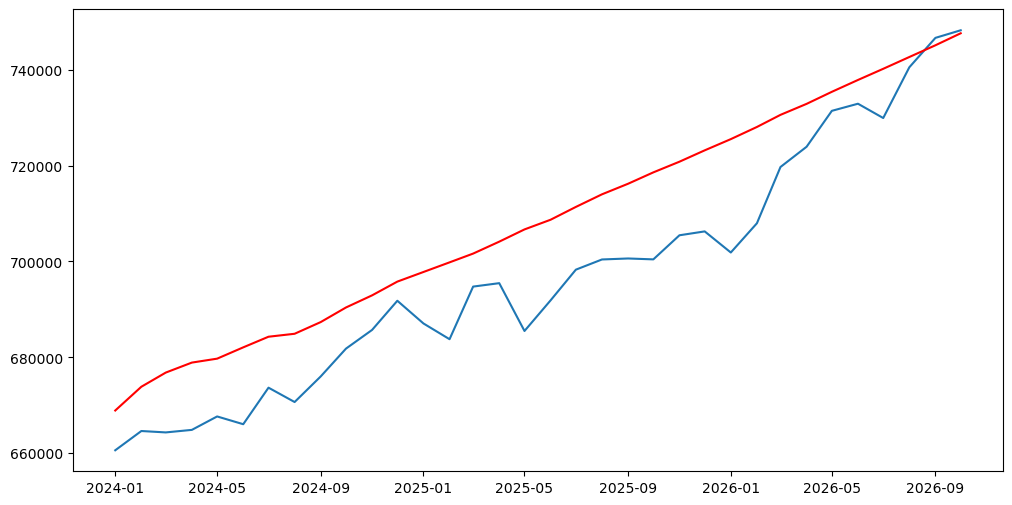

In [19]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test['RSAFS'])
plt.plot(predictions, color='red')
plt.show()

In [20]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['RSAFS'], predictions))
rmse = round(rmse, 3)

In [21]:
# Mean Absolute Percentage Error
abs_error = np.abs(test['RSAFS'] - predictions)
actual = test['RSAFS']
mape = np.round(np.mean(abs_error / actual), 3)

resultsDf = pd.DataFrame({
    'Method': ['Auto Regressive'],
    'RMSE': [rmse]
})

resultsDf
mape

0.017

In [22]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({
    'Method': ['Auto Regressive'],
    'MAPE': [mape],
    'RMSE': [rmse]
})

resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,12702.737,0.017


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (3, 0) model - AIC:7989.807420833127
Order of AR part: 3
Coefficients: const     3.606808e+05
ar.L1     1.019899e+00
ar.L2    -1.995735e-01
ar.L3     1.792429e-01
sigma2    6.104545e+07
dtype: float64


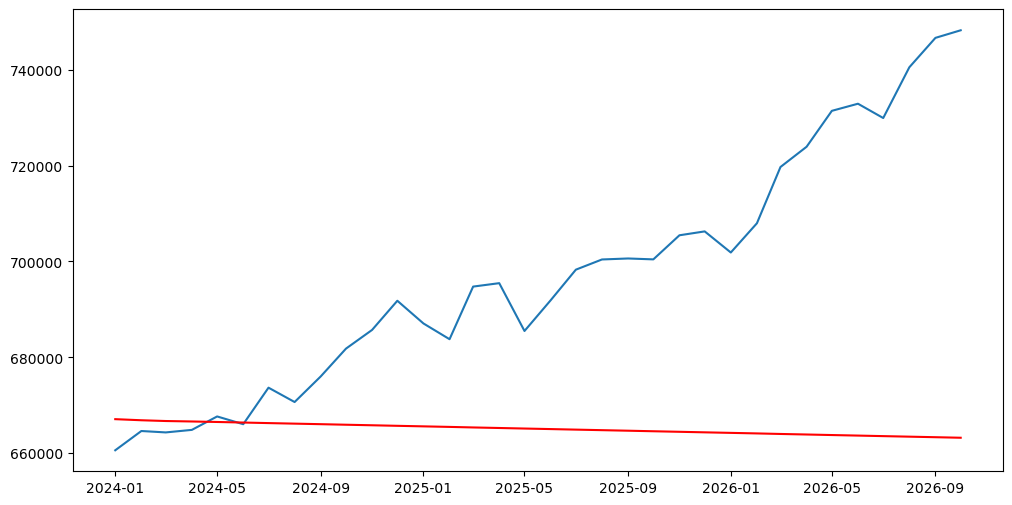

,Method,RMSE,MAPE
0,Auto Regressive,12702.737,0.017
0,Auto Regressive Moving average,41153.032,0.046


In [25]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Define the p and q parameters to take any value between 0 and 7
p = range(0, 7)
q = range(0,1)

# Generate all different combinations of p,q
pq = list(itertools.product(p,q))

best_aic = np.inf
best_pq = None
temp_model = None 

for param in pq: 
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit(method_kwargs={'maxiter': 500})

        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param

    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit(method_kwargs={'maxiter': 500})

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])

# Print the coefficients
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test['RSAFS'])
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['RSAFS'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['RSAFS']-predictions)
actual = test['RSAFS']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({
    'Method':['Auto Regressive Moving average '],
    'RMSE': [rmse],
    'MAPE': [mape]
})

resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level. 

Best SARIMA (0, 1, 0) x (1, 1, 1, 12) model - AIC:7562.746148006249


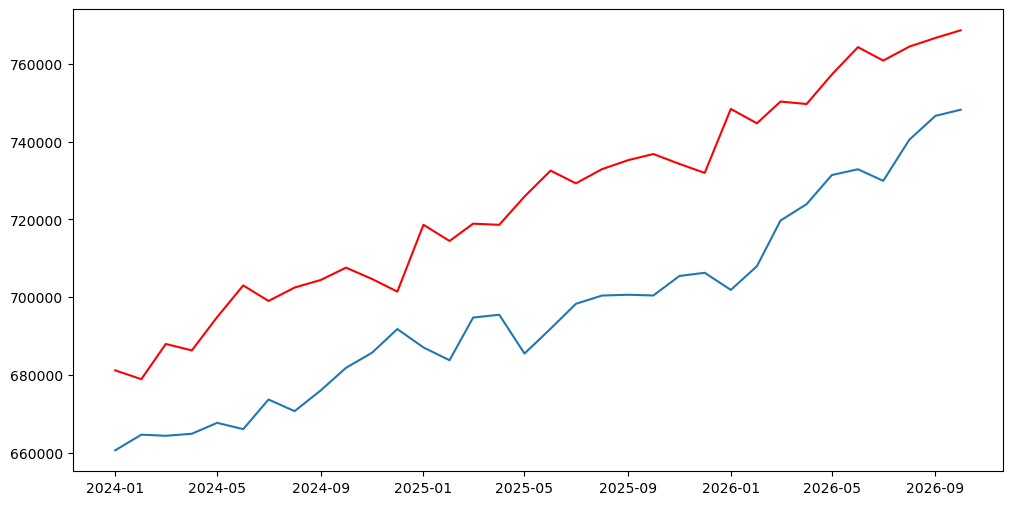

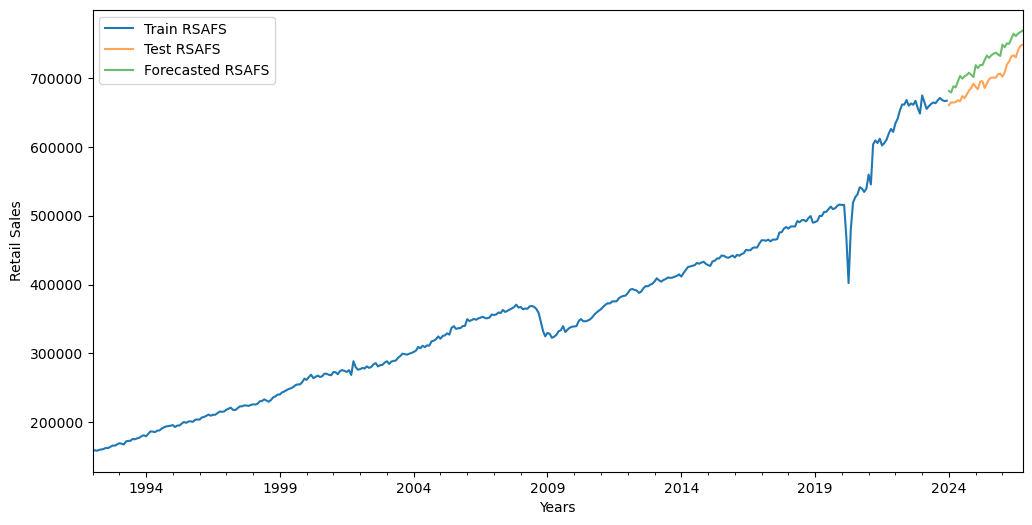

In [28]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:   
    for param_seasonal in seasonal_pdq: 
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test['RSAFS'])
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['RSAFS'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['RSAFS']-predictions)
actual = test['RSAFS']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({
    'Method':['Seasonal Autoregressive Integrated Moving Average'],
    'RMSE': [rmse],
    'MAPE': [mape]
})

resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf.index = [i for i in range(len(resultsDf))]
resultsDf

# Plotting the train, test and forecasted sales
axis = train['RSAFS'].plot(label='Train RSAFS', figsize=(12, 6))
test['RSAFS'].plot(ax=axis, label='Test RSAFS', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted RSAFS', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Retail Sales')
plt.legend(loc='best')
plt.show()
plt.close()

In [29]:
# Storing results in a dataframe

print(resultsDf)

                                              Method       RMSE   MAPE
0                                    Auto Regressive  12702.737  0.017
1                    Auto Regressive Moving average   41153.032  0.046
2  Seasonal Autoregressive Integrated Moving Average  29118.052  0.040
